# SINASC 2014–2024 — qualidade temporal em São Paulo
**IPT · Mestrado em Computação Aplicada · Big Data & Analytics**

Comparação descritiva de qualidade da informação e viabilidade amostral: capital, estado e restante do estado. Recorte principal **provisório**; nenhuma estimação causal ou preditiva.

Este notebook lê somente bases locais completas e grava somente `qualidade_sp_por_ano.csv`, na própria pasta de entrega. Execute com a **.venv deste projeto** (`.venv/Scripts/python.exe`).

## Resumo executivo

Foram encontrados e calculados **todos os onze anos (2014–2024)**, sem download. A capital apresenta MESPRENAT válido, validade essencial conjunta e retenção superiores ao estado e ao restante do estado em **11 de 11 anos**.

- **Capital:** 1.587.749 elegíveis B, dos quais 1.401.494 em T=1 e 186.255 em T=0; retenção acumulada de 94,61%.
- **Estado:** 5.811.572 elegíveis e 673.909 controles. **Restante:** 4.223.823 elegíveis e 487.654 controles. São recortes sobrepostos: estado = capital + restante.
- **Qualidade temporal da capital:** MESPRENAT válido de 98,45% em 2014 a 99,15% em 2024. A maior queda anual foi de 0,15 p.p. em 2020.
- **Atenção:** controles da capital caíram 58,44% de 2014 a 2024; maior queda anual em 2021 (17,73%). O total elegível caiu 30,48% no período.
- **Recomendação:** manter a capital como recorte principal provisório e o estado como alternativa de maior abrangência. Quantidade de controles não comprova precisão suficiente em todos os subgrupos nem identificação causal.

Resumo referente à execução local de 22/10/2026. A conclusão ao final é recalculada pelo notebook.

## 1. Contexto, critérios e limites

- **Unidade:** registro de nascido vivo, por ano de nascimento; não é acompanhamento longitudinal das mães.
- **Geografia por residência materna:** capital = `CODMUNRES=355030`; estado = prefixo `35`; restante = prefixo `35` e código diferente de `355030`. Estado contém capital e restante; nunca somar os três.
- **Especificação B:** gestação única (`GRAVIDEZ=1`), peso inteiro de 500 a 6.000 g e pré-natal iniciado nos meses 1–3 (T=1) ou 4–6 (T=0). Não excluir por covariáveis incompletas.
- **Denominadores:** preenchimento, validade e retenção usam todos os nascimentos do ano/recorte. Proporções T usam os elegíveis B. Totais do período são somas de contagens anuais; percentuais acumulados usam numeradores/denominadores somados.
- **Qualidade versus elegibilidade:** meses 7–9 e gestações múltiplas são categorias válidas fora de B; peso fora de 500–6.000 g é exclusão operacional, não erro presumido.
- **Temporalidade e causalidade:** mês de início e covariáveis são registrados no nascimento. Este levantamento não valida disponibilidade pré-tratamento, confundimento ou seleção de nascidos vivos. Não calcula associações com baixo peso, efeitos ou adequação de poder estatístico.

Regras preservadas da [comparação de 2024](../../outputs/qualidade_geografica_2024/RECOMENDACAO_RECORTE.md), do [dicionário local](../../docs/dados/DICIONARIO_ANALITICO_SINASC_2024.md) e do [piloto B](../../outputs/sinasc_sim_piloto_2024/LEIA_ME.txt). Caminhos conforme `src/temporal.py::caminhos_ano`. A documentação histórica não comprova estabilidade de mensuração; não serão inventadas equivalências entre campos.

In [1]:
from pathlib import Path
import sys
sys.dont_write_bytecode = True

import duckdb
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from IPython.display import display, Markdown, Image

cwd = Path.cwd().resolve()
raiz = next(p for p in [cwd, *cwd.parents]
            if (p / "src" / "visualizacao.py").is_file()
            and (p / "data" / "processed").is_dir())
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))
from src.visualizacao import CORES_IPT, aplicar_tema_base

ANOS = list(range(2014, 2025))
PASTA = raiz / "outputs" / "qualidade_geografica_2024"
SAIDA = PASTA / "qualidade_sp_por_ano.csv"
VARIAVEIS = ["MESPRENAT", "PESO", "GRAVIDEZ", "IDADEMAE", "ESCMAE2010",
             "RACACORMAE", "ESTCIVMAE", "PARIDADE", "QTDFILMORT"]
NOMES = {"sp_capital": "SP — capital", "sp_estado": "SP — estado",
         "sp_restante": "SP — restante"}
ORDEM = list(NOMES)
CORES = {"sp_capital": CORES_IPT["AZUL_PRINCIPAL"],
         "sp_estado": CORES_IPT["AZUL_CLARO"],
         "sp_restante": CORES_IPT["AZUL_ESCURO"]}
TRACOS = {"sp_capital": "solid", "sp_estado": "dot", "sp_restante": "dash"}
MARCAS = {"sp_capital": "circle", "sp_estado": "square", "sp_restante": "diamond"}
con = duckdb.connect()
con.execute("SET threads=4")
print("Ambiente:", sys.executable)
print("Versões:", "DuckDB", duckdb.__version__, "| pandas", pd.__version__)

Ambiente: C:\GitHub\data-science-projects\projetos\big-data-sinasc-causal-ml\.venv\Scripts\python.exe
Versões: DuckDB 1.5.5 | pandas 3.0.6


## 2. Disponibilidade local e estrutura

A existência de cada arquivo é verificada antes da leitura. A busca está limitada aos dois caminhos locais documentados em `data/processed/`; não há download ou conversão. Nomes de colunas são comparados sem distinção de caixa, preservando valores originais. Campo ausente é registrado como **indisponível**, não como zero de preenchimento; sem data ou geografia, o ano não pode ser calculado.

In [2]:
inventario = []
fontes = {}
campos_por_ano = {}
for ano in ANOS:
    candidatos = [
        raiz / "data" / "processed" / f"sinasc_{ano}.parquet",
        raiz / "data" / "processed" / "sinasc" / f"sinasc_{ano}.parquet",
    ]
    caminho = next((p for p in candidatos if p.is_file()), None)
    if caminho is None:
        inventario.append({"ano": ano, "disponivel": False, "fonte": "",
                           "n_colunas": None, "campos_ausentes": "",
                           "normalizacao_caixa": False})
        continue
    estrutura = con.execute("DESCRIBE SELECT * FROM read_parquet(?)",
                            [str(caminho)]).fetchall()
    campos = {r[0].upper(): r[0] for r in estrutura}
    faltantes = sorted(set(VARIAVEIS + ["CODMUNRES", "DTNASC"]) - set(campos))
    fontes[ano] = caminho
    campos_por_ano[ano] = campos
    inventario.append({
        "ano": ano, "disponivel": True,
        "fonte": caminho.relative_to(raiz).as_posix(),
        "n_colunas": len(estrutura), "campos_ausentes": ", ".join(faltantes),
        "normalizacao_caixa": any(k != v for k, v in campos.items()),
    })
inventario = pd.DataFrame(inventario)
display(inventario)
anos_faltantes = inventario.loc[~inventario.disponivel, "ano"].tolist()
print("Anos sem base local:", anos_faltantes or "nenhum")
assert fontes, "Nenhuma base local disponível; análise interrompida."

,ano,disponivel,fonte,n_colunas,campos_ausentes,normalizacao_caixa
0,2014,True,data/processed/sinasc/sinasc_2014.parquet,61,,False
1,2015,True,data/processed/sinasc/sinasc_2015.parquet,61,,False
2,2016,True,data/processed/sinasc/sinasc_2016.parquet,61,,True
3,2017,True,data/processed/sinasc/sinasc_2017.parquet,61,,False
4,2018,True,data/processed/sinasc/sinasc_2018.parquet,61,,False
5,2019,True,data/processed/sinasc/sinasc_2019.parquet,61,,False
6,2020,True,data/processed/sinasc/sinasc_2020.parquet,61,,False
7,2021,True,data/processed/sinasc/sinasc_2021.parquet,61,,False
8,2022,True,data/processed/sinasc/sinasc_2022.parquet,61,,False
9,2023,True,data/processed/sinasc/sinasc_2023.parquet,62,,True


Anos sem base local: nenhum


## 3. Regras de preenchimento e validade

| Campo | Regra preservada |
|---|---|
| MESPRENAT | Inteiros 1–9 válidos; 99 ignorado; demais códigos informados inválidos. |
| GRAVIDEZ | 1–3 válidos; 9 ignorado. |
| PESO | Inteiro 500–6.000 g válido **operacional**; demais inteiros fora da faixa analítica. |
| ESCMAE2010 | 0–5 válidos; 9 ignorado. Zero é categoria válida. |
| RACACORMAE | 1–5 válidos; código de ignorado não confirmado. |
| ESTCIVMAE | 1–5 válidos; 9 ignorado. |
| PARIDADE | 0/1 válidos; não recalcular a partir de outros campos. |
| IDADEMAE e QTDFILMORT | Preenchimento = não nulo/vazio. Limites e sentinelas não confirmados no dicionário usado em 2024; validade substantiva **não avaliada**. Código 99 sinalizado sem reclassificação. |

Ausente = nulo ou vazio após remoção de espaços. Forma não inteira é invalidade de formato; em IDADEMAE/QTDFILMORT, inteiros preenchidos permanecem com validade não confirmada. Não aplicar silenciosamente recodificações de outros notebooks. Validade documental não implica ausência de erro de mensuração.

O CSV contém contagens e percentuais por variável, disponibilidade, códigos 99 não classificados e exclusões sequenciais. Células vazias de validade em IDADEMAE/QTDFILMORT significam **não avaliada**, não zero.

In [3]:
DOMINIOS = {
    "MESPRENAT": list(range(1, 10)), "GRAVIDEZ": [1, 2, 3],
    "ESCMAE2010": list(range(6)), "RACACORMAE": [1, 2, 3, 4, 5],
    "ESTCIVMAE": [1, 2, 3, 4, 5], "PARIDADE": [0, 1],
}
IGNORADOS = {"MESPRENAT": 99, "GRAVIDEZ": 9, "ESCMAE2010": 9, "ESTCIVMAE": 9}
STATUS = ["ausente", "ignorado", "invalido", "valido",
          "fora_faixa", "nao_confirmado"]
NAO_AVALIADOS = {"IDADEMAE", "QTDFILMORT"}

def classificar_sql(campo):
    inteiro = (f"regexp_full_match({campo}, '[0-9]+') "
               f"AND try_cast({campo} AS BIGINT) IS NOT NULL")
    valor = f"try_cast({campo} AS BIGINT)"
    regra = f"CASE WHEN {campo} IS NULL THEN 'ausente' "
    if campo in IGNORADOS:
        regra += f"WHEN ({inteiro}) AND {valor}={IGNORADOS[campo]} THEN 'ignorado' "
    regra += f"WHEN NOT ({inteiro}) THEN 'invalido' "
    if campo in DOMINIOS:
        codigos = ",".join(map(str, DOMINIOS[campo]))
        regra += f"WHEN {valor} IN ({codigos}) THEN 'valido' ELSE 'invalido' "
    elif campo == "PESO":
        regra += f"WHEN {valor} BETWEEN 500 AND 6000 THEN 'valido' ELSE 'fora_faixa' "
    else:
        regra += "ELSE 'nao_confirmado' "
    return regra + f"END AS s_{campo}"

def contar_sql(condicao, nome):
    return f"count(*) FILTER (WHERE {condicao}) AS {nome}"

def percentual(numerador, denominador):
    return 100 * numerador / denominador if denominador else float("nan")

## 4. Agregação anual com DuckDB

Cada arquivo é lido separadamente. As agregações são feitas diretamente em DuckDB; somente resultados pequenos são materializados em pandas. Estado = capital + restante. Anos ou campos indisponíveis não são imputados. Não são usados resultados causais já existentes no projeto.

In [4]:
resultados = []
checagens_datas = []
for ano, caminho in fontes.items():
    campos = campos_por_ano[ano]
    if not {"CODMUNRES", "DTNASC"}.issubset(campos):
        print(f"{ano}: sem data/geografia; não calculado.")
        continue

    def coluna(campo):
        original = campos[campo].replace('"', '""')
        return f'nullif(trim(CAST("{original}" AS VARCHAR)), \'\')'

    selecao = [
        f"{coluna(v)} AS {v}" if v in campos else f"NULL::VARCHAR AS {v}"
        for v in VARIAVEIS
    ]
    selecao += [f"{coluna('CODMUNRES')} AS municipio",
                f"{coluna('DTNASC')} AS data_nascimento"]
    con.execute("CREATE OR REPLACE TEMP VIEW normalizado AS SELECT "
                + ", ".join(selecao) + " FROM read_parquet("
                + "'" + caminho.as_posix().replace("'", "''") + "')")
    datas = con.execute("""
        SELECT count(*) AS n_sp_arquivo,
               count(*) FILTER (WHERE year(try_strptime(data_nascimento, '%d%m%Y')) = ?)
                   AS n_sp_ano
        FROM normalizado WHERE substr(municipio, 1, 2) = '35'
    """, [ano]).fetchone()
    checagens_datas.append({"ano": ano, "n_sp_arquivo": datas[0],
                           "n_sp_ano": datas[1],
                           "n_data_fora_ano_ou_invalida": datas[0] - datas[1]})

    classificacoes = ", ".join(classificar_sql(v) for v in VARIAVEIS)
    con.execute(f"""
        CREATE OR REPLACE TEMP VIEW classificado AS
        SELECT *, {classificacoes},
               CASE WHEN municipio='355030' THEN 'sp_capital'
                    ELSE 'sp_restante' END AS territorio
        FROM normalizado
        WHERE substr(municipio, 1, 2)='35'
          AND year(try_strptime(data_nascimento, '%d%m%Y'))={ano}
    """)
    erro_essencial = " OR ".join(
        f"s_{v} IN ('ausente','ignorado','invalido')" for v in VARIAVEIS[:3]
    )
    elegivel = ("try_cast(GRAVIDEZ AS INT)=1 "
                "AND try_cast(PESO AS INT) BETWEEN 500 AND 6000 "
                "AND try_cast(MESPRENAT AS INT) BETWEEN 1 AND 6")
    condicoes = {
        "essenciais_validas": "s_MESPRENAT='valido' AND s_GRAVIDEZ='valido' AND s_PESO='valido'",
        "elegiveis": elegivel,
        "t1": f"({elegivel}) AND try_cast(MESPRENAT AS INT) BETWEEN 1 AND 3",
        "t0": f"({elegivel}) AND try_cast(MESPRENAT AS INT) BETWEEN 4 AND 6",
        "excl_qualidade_essenciais": erro_essencial,
        "excl_populacao_gestacao_multipla": f"NOT ({erro_essencial}) AND try_cast(GRAVIDEZ AS INT) IN (2,3)",
        "excl_populacao_peso_fora_faixa": f"NOT ({erro_essencial}) AND try_cast(GRAVIDEZ AS INT)=1 AND s_PESO='fora_faixa'",
        "excl_populacao_mes_7_9": f"NOT ({erro_essencial}) AND try_cast(GRAVIDEZ AS INT)=1 AND s_PESO='valido' AND try_cast(MESPRENAT AS INT) BETWEEN 7 AND 9",
    }
    agregacoes = ["count(*) AS n_nascimentos"]
    for v in VARIAVEIS:
        for status in STATUS:
            agregacoes.append(contar_sql(f"s_{v}='{status}'", f"n_{v.lower()}_{status}"))
        if v in NAO_AVALIADOS:
            agregacoes.append(contar_sql(f"{v}='99'", f"n_{v.lower()}_99_sem_classificacao"))
    agregacoes += [contar_sql(condicao, f"n_{nome}")
                  for nome, condicao in condicoes.items()]
    sql = f"""
        SELECT CASE WHEN grouping(territorio)=1 THEN 'sp_estado'
                    ELSE territorio END AS recorte_id,
               {", ".join(agregacoes)}
        FROM classificado GROUP BY GROUPING SETS ((territorio), ())
    """
    anual = con.execute(sql).df()
    for linha in anual.to_dict("records"):
        linha.update(ano=ano, recorte=NOMES[linha["recorte_id"]],
                     fonte=caminho.relative_to(raiz).as_posix())
        for v in VARIAVEIS:
            prefixo = v.lower()
            linha[f"{prefixo}_disponivel"] = v in campos
            if v not in campos:
                for k in list(linha):
                    if k.startswith(f"n_{prefixo}_"):
                        linha[k] = None
                linha[f"n_{prefixo}_preenchido"] = None
            else:
                linha[f"n_{prefixo}_preenchido"] = (
                    linha["n_nascimentos"] - linha[f"n_{prefixo}_ausente"])
            if v in NAO_AVALIADOS:
                linha[f"n_{prefixo}_valido"] = None
            for medida in STATUS + ["preenchido"]:
                valor = linha[f"n_{prefixo}_{medida}"]
                linha[f"pct_{prefixo}_{medida}"] = (
                    percentual(valor, linha["n_nascimentos"])
                    if valor is not None else None)
        if not set(VARIAVEIS[:3]).issubset(campos):
            for nome in condicoes:
                linha[f"n_{nome}"] = None
        for nome in condicoes:
            valor = linha[f"n_{nome}"]
            denominador = linha["n_elegiveis"] if nome in ["t1", "t0"] else linha["n_nascimentos"]
            linha[f"pct_{nome}"] = percentual(valor, denominador) if valor is not None else None
        linha["limitacao_validade"] = "IDADEMAE e QTDFILMORT: validade substantiva nao avaliada; 99 nao reclassificado."
        resultados.append(linha)
    print(f"{ano}: {datas[1]:,} nascimentos no estado; três recortes calculados.")

dados = pd.DataFrame(resultados).sort_values(["ano", "recorte_id"]).reset_index(drop=True)
colunas_inicio = ["ano", "recorte_id", "recorte", "fonte", "n_nascimentos",
                  "n_elegiveis", "n_t1", "n_t0", "pct_elegiveis", "pct_t0"]
dados = dados[colunas_inicio + [c for c in dados if c not in colunas_inicio]]
datas_anuais = pd.DataFrame(checagens_datas)
display(datas_anuais)

2014: 625,687 nascimentos no estado; três recortes calculados.


2015: 634,026 nascimentos no estado; três recortes calculados.


2016: 601,437 nascimentos no estado; três recortes calculados.


2017: 611,803 nascimentos no estado; três recortes calculados.


2018: 606,146 nascimentos no estado; três recortes calculados.


2019: 583,191 nascimentos no estado; três recortes calculados.


... (2 outputs left out)

2022: 512,520 nascimentos no estado; três recortes calculados.


2023: 503,910 nascimentos no estado; três recortes calculados.


2024: 470,887 nascimentos no estado; três recortes calculados.


,ano,n_sp_arquivo,n_sp_ano,n_data_fora_ano_ou_invalida
0,2014,625687,625687,0
1,2015,634026,634026,0
2,2016,601437,601437,0
3,2017,611803,611803,0
4,2018,606146,606146,0
5,2019,583191,583191,0
6,2020,552310,552310,0
7,2021,525239,525239,0
8,2022,512520,512520,0
9,2023,503910,503910,0


## 5. Validações básicas e exportação

Verificações limitadas à chave ano/recorte, composição territorial, contagens dos grupos, partição dos status, exclusões e denominadores. Os valores de 2024 são reconciliados com a comparação já entregue; os três arquivos anteriores não são alterados. O CSV usa UTF-8 com BOM, separador `;`, decimal ponto e percentuais em escala 0–100.

In [5]:
assert not dados.duplicated(["ano", "recorte_id"]).any()
assert set(dados.recorte_id) == set(ORDEM)
assert len(dados) == 3 * dados.ano.nunique()
assert (dados.n_elegiveis == dados.n_t1 + dados.n_t0).all()
assert (dados.n_elegiveis <= dados.n_nascimentos).all()

contagens = [c for c in dados if c.startswith("n_")]
for ano, grupo in dados.groupby("ano"):
    territorial = grupo.set_index("recorte_id")
    assert territorial.loc["sp_estado", "n_nascimentos"] == (
        datas_anuais.set_index("ano").loc[ano, "n_sp_ano"])
    for coluna in contagens:
        valores = territorial[coluna]
        if valores.notna().all():
            assert valores["sp_estado"] == valores["sp_capital"] + valores["sp_restante"]

exclusoes = [c for c in dados if c.startswith("n_excl_")]
assert (dados.n_nascimentos == dados.n_elegiveis + dados[exclusoes].sum(axis=1)).all()
for v in VARIAVEIS:
    partes = [f"n_{v.lower()}_{s}" for s in STATUS]
    presentes = dados[f"{v.lower()}_disponivel"]
    assert (dados.loc[presentes, partes].fillna(0).sum(axis=1)
            == dados.loc[presentes, "n_nascimentos"]).all()

for coluna in [c for c in dados if c.startswith("pct_")]:
    numerador = dados["n_" + coluna[4:]]
    denominador = dados.n_elegiveis if coluna in ["pct_t1", "pct_t0"] else dados.n_nascimentos
    esperado = 100 * numerador / denominador
    assert dados[coluna].isna().equals(esperado.isna())
    assert ((dados[coluna] - esperado).abs().dropna() < 1e-9).all()

referencia = pd.read_csv(PASTA / "comparacao_recortes_2024.csv", sep=";")
for recorte in ["sp_capital", "sp_estado"]:
    antigo = referencia.set_index("recorte_id").loc[recorte]
    atual = dados.set_index(["ano", "recorte_id"]).loc[(2024, recorte)]
    comuns = [c for c in dados if c in referencia and c.startswith(("n_", "pct_"))]
    for c in comuns:
        if pd.isna(antigo[c]) and pd.isna(atual[c]):
            continue
        assert abs(float(antigo[c]) - float(atual[c])) <= 0.00000051, (recorte, c)

# O único arquivo de dados gravado por este notebook.
dados.to_csv(SAIDA, sep=";", index=False, encoding="utf-8-sig", float_format="%.6f")
reaberto = pd.read_csv(SAIDA, sep=";")
assert reaberto.shape == dados.shape
for c in contagens:
    assert reaberto[c].isna().equals(dados[c].isna())
    preenchidos = dados[c].notna()
    assert (reaberto.loc[preenchidos, c] == dados.loc[preenchidos, c]).all()
for c in [c for c in dados if c.startswith("pct_")]:
    assert ((reaberto[c] - dados[c]).abs().dropna() <= 0.00000051).all()
print(f"Validações concluídas: {len(dados)} linhas, {dados.ano.nunique()} anos, três recortes.")
print("CSV reaberto:", SAIDA.relative_to(raiz))

Validações concluídas: 33 linhas, 11 anos, três recortes.
CSV reaberto: outputs\qualidade_geografica_2024\qualidade_sp_por_ano.csv


## 6. Tabela resumida e dimensão da amostra

A tabela anual compara o indicador central nos três recortes e mostra o tamanho da amostra da capital. Todos os indicadores por ano e recorte, inclusive covariáveis e exclusões, estão no CSV. A tabela acumulada usa pesos proporcionais ao número de nascimentos, não médias simples dos percentuais.

In [6]:
def numero(valor, casas=0):
    if pd.isna(valor):
        return "—"
    return f"{valor:,.{casas}f}".replace(",", "§").replace(".", ",").replace("§", ".")

def tabela_ipt(tabela, percentuais=()):
    formatos = {c: (lambda x: numero(x, 2)) if c in percentuais
                else (lambda x: numero(x, 0))
                for c in tabela.select_dtypes(include="number").columns}
    return (tabela.style.format(formatos, na_rep="—")
            .set_table_styles([
                {"selector": "th", "props": [("background-color", "#00598E"),
                                           ("color", "white"), ("padding", "7px")]},
                {"selector": "td", "props": [("padding", "6px 9px"),
                                           ("border-bottom", "1px solid #D9E7EE")]},
                {"selector": "table", "props": [("font-family", "Arial"),
                                               ("font-size", "13px")]}
            ]))

mes = dados.pivot(index="ano", columns="recorte_id", values="pct_mesprenat_valido")
capital = dados[dados.recorte_id == "sp_capital"].set_index("ano")
resumo = pd.DataFrame({
    "Mês válido capital (%)": mes.sp_capital,
    "Mês válido estado (%)": mes.sp_estado,
    "Mês válido restante (%)": mes.sp_restante,
    "Elegíveis capital": capital.n_elegiveis,
    "T=1 capital": capital.n_t1,
    "T=0 capital": capital.n_t0,
    "Retenção capital (%)": capital.pct_elegiveis,
})
resumo.index.name = "Ano"
display(tabela_ipt(resumo, [c for c in resumo if "(%)" in c]))

totais = dados.groupby("recorte_id")[[
    "n_nascimentos", "n_elegiveis", "n_t1", "n_t0", "n_mesprenat_valido"]].sum().loc[ORDEM]
totais["Retenção (%)"] = 100 * totais.n_elegiveis / totais.n_nascimentos
totais["Mês válido (%)"] = 100 * totais.n_mesprenat_valido / totais.n_nascimentos
totais["Controles (%)"] = 100 * totais.n_t0 / totais.n_elegiveis
totais_exibicao = totais.drop(columns="n_mesprenat_valido").rename(columns={
    "n_nascimentos": "Nascimentos", "n_elegiveis": "Elegíveis",
    "n_t1": "T=1", "n_t0": "T=0"})
totais_exibicao.index = totais_exibicao.index.map(NOMES)
display(tabela_ipt(totais_exibicao, ["Retenção (%)", "Mês válido (%)", "Controles (%)"]))

,Mês válido capital (%),Mês válido estado (%),Mês válido restante (%),Elegíveis capital,T=1 capital,T=0 capital,Retenção capital (%)
Ano,,,,,,,
2014,"98,45","95,17","93,89",164.987,140.639,24.348,"93,83"
2015,"98,48","95,15","93,86",165.787,141.442,24.345,"94,03"
2016,"98,80","96,74","95,95",158.025,136.923,21.102,"94,45"
2017,"99,01","97,74","97,25",160.429,141.470,18.959,"94,76"
2018,"99,03","98,08","97,73",156.806,138.992,17.814,"94,83"
2019,"98,95","98,20","97,91",150.427,132.846,17.581,"94,85"
2020,"98,80","97,92","97,60",139.283,123.840,15.443,"94,66"
2021,"98,90","98,17","97,91",129.761,117.056,12.705,"94,90"
2022,"99,10","98,33","98,07",125.306,112.936,12.370,"94,89"


,Nascimentos,Elegíveis,T=1,T=0,Retenção (%),Mês válido (%),Controles (%)
recorte_id,,,,,,,
SP — capital,1.678.121,1.587.749,1.401.494,186.255,"94,61","98,87","11,73"
SP — estado,6.227.156,5.811.572,5.137.663,673.909,"93,33","97,39","11,60"
SP — restante,4.549.035,4.223.823,3.736.169,487.654,"92,85","96,84","11,55"


## 7. Evolução da validade de MESPRENAT

Percentual de códigos 1–9 entre todos os nascimentos do ano/recorte. **Eixo vertical ampliado (93%–100%)** para mostrar diferenças em pontos percentuais. As linhas do estado e da capital se sobrepõem populacionalmente; capital versus restante é a comparação territorial disjunta.

As figuras são produzidas com Plotly e o tema IPT de `src/visualizacao.py`. Cada saída contém o objeto interativo e uma imagem PNG de apoio, permitindo leitura estática sem acesso à internet. A interação depende do suporte Plotly do visualizador Jupyter.

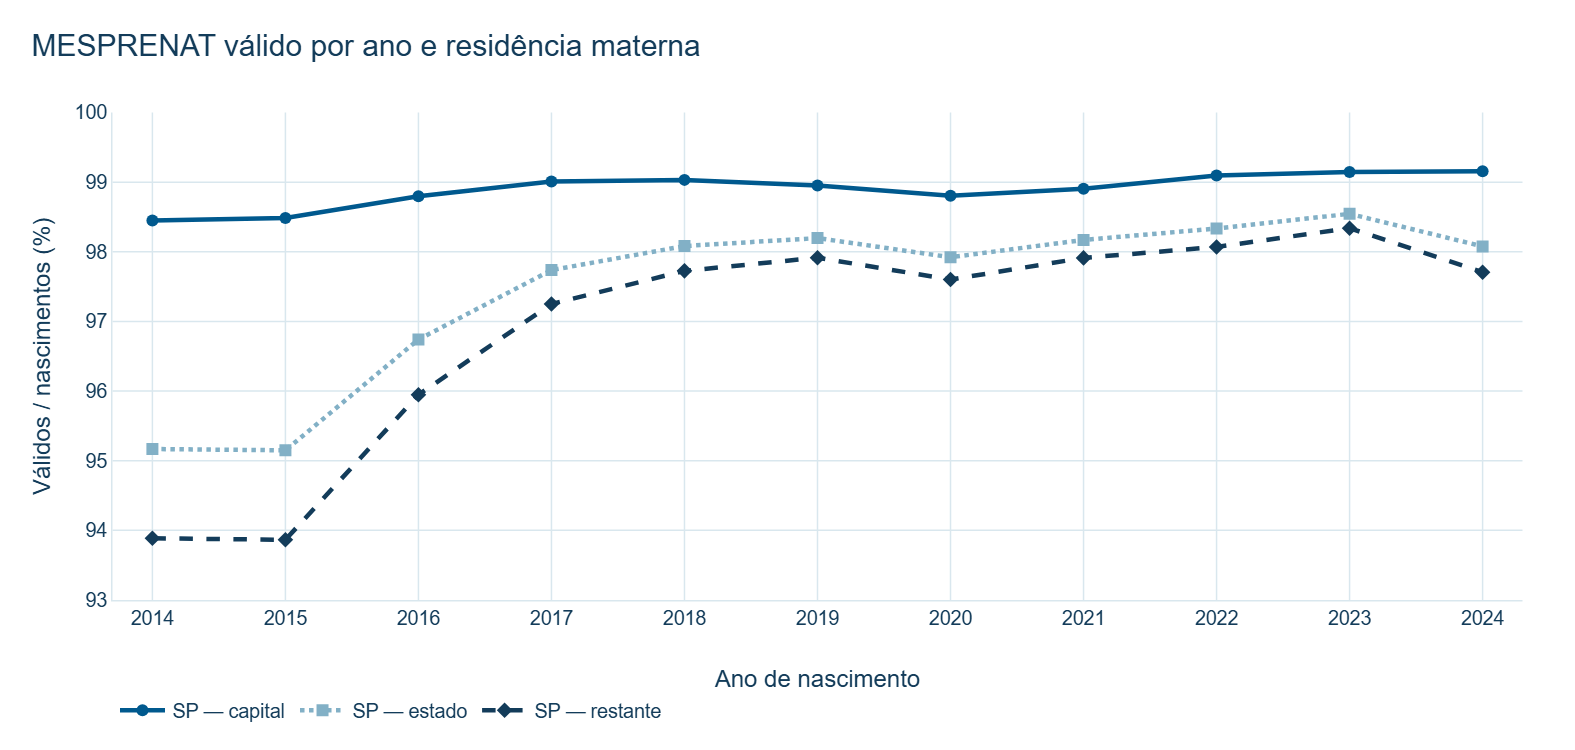

In [7]:
import base64
import json

def exibir_plotly(figura):
    # PNG de apoio e representação interativa na mesma saída, sem arquivos extras.
    png = figura.to_image(format="png", scale=1.5)
    display({
        "application/vnd.plotly.v1+json": json.loads(pio.to_json(figura)),
        "image/png": base64.b64encode(png).decode("ascii"),
        "text/plain": figura.layout.title.text,
    }, raw=True)

fig_mes = go.Figure()
for recorte in ORDEM:
    serie = dados[dados.recorte_id == recorte].set_index("ano").reindex(ANOS)
    fig_mes.add_scatter(
        x=ANOS, y=serie.pct_mesprenat_valido.tolist(),
        customdata=serie[["n_mesprenat_valido", "n_nascimentos"]].values.tolist(),
        name=NOMES[recorte], mode="lines+markers", connectgaps=False,
        line=dict(color=CORES[recorte], dash=TRACOS[recorte], width=3),
        marker=dict(symbol=MARCAS[recorte], size=8),
        hovertemplate="Ano %{x}<br>Válido: %{y:.2f}%<br>Válidos: %{customdata[0]:,.0f}"
                      "<br>Nascimentos: %{customdata[1]:,.0f}<extra>%{fullData.name}</extra>",
    )
aplicar_tema_base(fig_mes, "MESPRENAT válido por ano e residência materna")
fig_mes.update_layout(width=1050, height=500, separators=",.",
                      legend=dict(orientation="h", y=-0.18, x=0),
                      margin=dict(l=75, r=35, t=75, b=95))
fig_mes.update_xaxes(title="Ano de nascimento", tickmode="array", tickvals=ANOS,
                     tickformat="d", range=[2013.7, 2024.3])
fig_mes.update_yaxes(title="Válidos / nascimentos (%)", range=[93, 100], dtick=1)
exibir_plotly(fig_mes)

**Leitura do gráfico:** a vantagem da capital sobre o restante do estado varia de **0,81 a 4,62 p.p.**; sobre o estado, de **0,60 a 3,33 p.p.** Os menores níveis no estado/restante ocorrem em 2014–2015, e há melhora posterior. Em 2024, a validade recua de **98,54% para 98,08% no estado** e de **98,34% para 97,71% no restante**, enquanto a capital passa de **99,14% para 99,15%**. São diferenças descritivas de registro; não há atribuição de causa.

## 8. Grupos T=1 e T=0 na especificação B

Contagens anuais após gestação única, peso 500–6.000 g e início nos meses 1–6. Os painéis têm **escalas verticais diferentes** para tornar visível a evolução dos controles; não comparar a altura das curvas entre os painéis. Nenhuma taxa de baixo peso é usada para escolher o recorte.

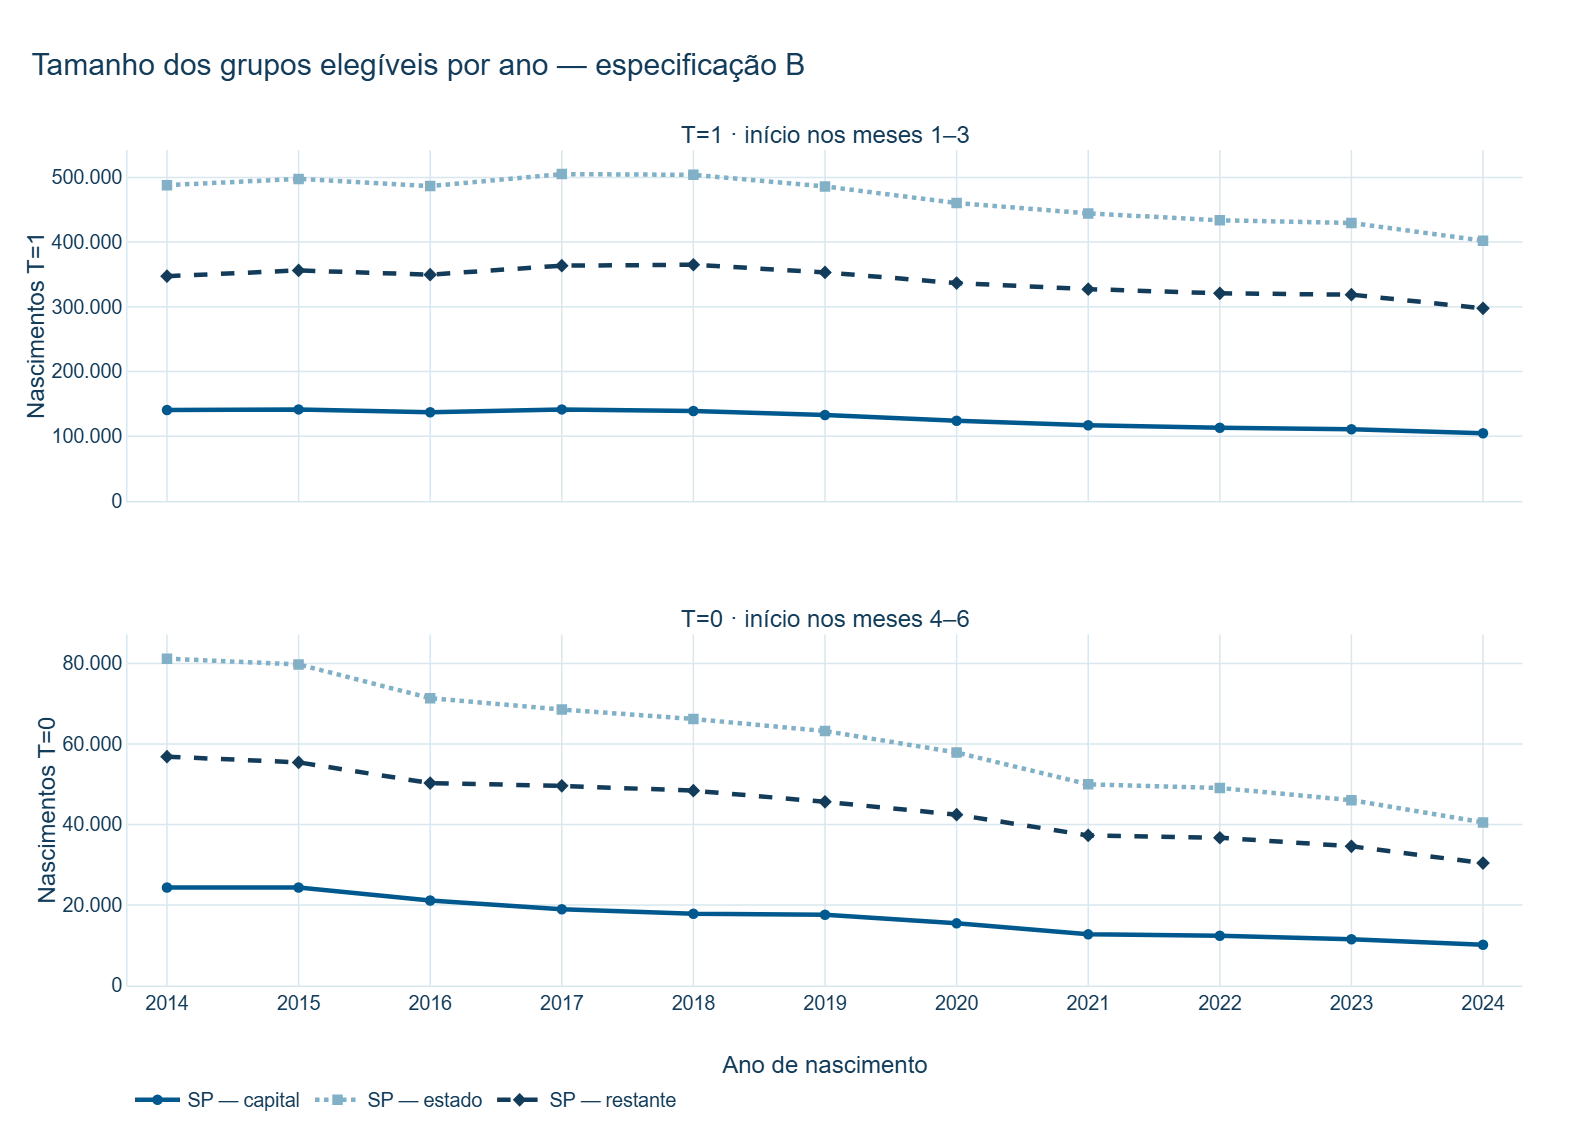

In [8]:
fig_grupos = make_subplots(
    rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.16,
    subplot_titles=["T=1 · início nos meses 1–3", "T=0 · início nos meses 4–6"],
)
for linha, coluna in [(1, "n_t1"), (2, "n_t0")]:
    for recorte in ORDEM:
        serie = dados[dados.recorte_id == recorte].set_index("ano").reindex(ANOS)
        fig_grupos.add_scatter(
            x=ANOS, y=serie[coluna].tolist(), mode="lines+markers", connectgaps=False,
            name=NOMES[recorte], legendgroup=recorte, showlegend=linha == 1,
            line=dict(color=CORES[recorte], dash=TRACOS[recorte], width=3),
            marker=dict(symbol=MARCAS[recorte], size=7),
            hovertemplate="Ano %{x}<br>Nascimentos: %{y:,.0f}<extra>%{fullData.name}</extra>",
            row=linha, col=1,
        )
aplicar_tema_base(fig_grupos, "Tamanho dos grupos elegíveis por ano — especificação B")
fig_grupos.update_layout(
    width=1050, height=760, separators=",.",
    legend=dict(orientation="h", y=-0.11, x=0),
    margin=dict(l=85, r=35, t=100, b=95),
)
fig_grupos.update_xaxes(tickmode="array", tickvals=ANOS, tickformat="d",
                       range=[2013.7, 2024.3])
fig_grupos.update_xaxes(title="Ano de nascimento", row=2, col=1)
fig_grupos.update_yaxes(title="Nascimentos T=1", rangemode="tozero",
                       tickformat=",.0f", row=1, col=1)
fig_grupos.update_yaxes(title="Nascimentos T=0", rangemode="tozero",
                       tickformat=",.0f", row=2, col=1)
exibir_plotly(fig_grupos)

**Leitura do gráfico:** na capital, T=0 passa de **24.348 (2014)** a **10.118 (2024)**, e sua participação entre elegíveis cai de **14,76% para 8,82%**. A maior redução anual de controles ocorre em **2021: 15.443 → 12.705 (−17,73%)**. A maior queda anual de elegíveis ocorre em **2020: 150.427 → 139.283 (−7,41%)**. A combinação de menos nascimentos e menor participação de T=0 reduz a amostra; a melhora de preenchimento não compensa essa redução. Não foi investigada a causa dessas mudanças.

## 9. Covariáveis e oscilações anuais

A vantagem deve ser avaliada por campo, sem presumir superioridade uniforme. A tabela abaixo compara a capital ao restante do estado, usando validade documentada quando disponível e preenchimento para IDADEMAE/QTDFILMORT. Valores em pontos percentuais; não são efeitos causais.

Quedas são descritas por sua magnitude observada, sem limiar estatístico inventado. Uma redução de nascimentos ou de controles pode refletir composição da população e distribuição do mês de início; esta análise não atribui uma causa.

In [9]:
indicadores = {
    "MESPRENAT válido": "pct_mesprenat_valido",
    "GRAVIDEZ válida": "pct_gravidez_valido",
    "PESO na faixa": "pct_peso_valido",
    "IDADEMAE preenchida": "pct_idademae_preenchido",
    "ESCMAE2010 válida": "pct_escmae2010_valido",
    "RACACORMAE válida": "pct_racacormae_valido",
    "ESTCIVMAE válida": "pct_estcivmae_valido",
    "PARIDADE válida": "pct_paridade_valido",
    "QTDFILMORT preenchido": "pct_qtdfilmort_preenchido",
}
comparacoes = []
for nome, coluna in indicadores.items():
    tabela = dados.pivot(index="ano", columns="recorte_id", values=coluna)
    delta = tabela.sp_capital - tabela.sp_restante
    comparacoes.append({
        "Indicador": nome,
        "Mínimo capital (%)": tabela.sp_capital.min(),
        "Máximo capital (%)": tabela.sp_capital.max(),
        "Menor vantagem (p.p.)": delta.min(),
        "Maior vantagem (p.p.)": delta.max(),
        "Anos capital superior": int((delta > 1e-9).sum()),
        "Anos capital inferior": int((delta < -1e-9).sum()),
    })
comparacao_variaveis = pd.DataFrame(comparacoes).set_index("Indicador")
display(tabela_ipt(comparacao_variaveis, comparacao_variaveis.columns[:4]))

variacoes = dados.sort_values(["recorte_id", "ano"]).copy()
grupo = variacoes.groupby("recorte_id")
variacoes["delta_mes_valido_pp"] = grupo.pct_mesprenat_valido.diff()
variacoes["variacao_elegiveis_pct"] = grupo.n_elegiveis.pct_change(fill_method=None) * 100
variacoes["variacao_t0_pct"] = grupo.n_t0.pct_change(fill_method=None) * 100
# Sem conectar variações entre anos não consecutivos.
nao_consecutivo = grupo.ano.diff() != 1
variacoes.loc[nao_consecutivo, ["delta_mes_valido_pp",
    "variacao_elegiveis_pct", "variacao_t0_pct"]] = float("nan")
quedas = []
for recorte in ORDEM:
    sub = variacoes[variacoes.recorte_id == recorte]
    for coluna, nome in [
        ("delta_mes_valido_pp", "Maior queda de MESPRENAT (p.p.)"),
        ("variacao_elegiveis_pct", "Maior queda de elegíveis (%)"),
        ("variacao_t0_pct", "Maior queda de controles (%)"),
    ]:
        validos = sub.dropna(subset=[coluna])
        if not validos.empty:
            linha = validos.loc[validos[coluna].idxmin()]
            quedas.append({"Recorte": NOMES[recorte], "Indicador": nome,
                           "Ano": int(linha.ano), "Variação": linha[coluna]})
quedas = pd.DataFrame(quedas)
display(tabela_ipt(quedas, ["Variação"]))

,Mínimo capital (%),Máximo capital (%),Menor vantagem (p.p.),Maior vantagem (p.p.),Anos capital superior,Anos capital inferior
Indicador,,,,,,
MESPRENAT válido,"98,45","99,15","0,81","4,62",11,0
GRAVIDEZ válida,"99,98","100,00","-0,00","0,08",10,1
PESO na faixa,"99,89","99,93","0,00","0,07",11,0
IDADEMAE preenchida,"100,00","100,00","0,00","0,00",1,0
ESCMAE2010 válida,"99,82","99,99","0,12","1,62",11,0
RACACORMAE válida,"99,87","99,98","0,38","2,34",11,0
ESTCIVMAE válida,"99,72","99,94","0,19","0,72",11,0
PARIDADE válida,"100,00","100,00","0,00","0,00",0,0
QTDFILMORT preenchido,"99,70","99,99","0,23","3,41",11,0


,Recorte,Indicador,Ano,Variação
0,SP — capital,Maior queda de MESPRENAT (p.p.),2.020,"-0,15"
1,SP — capital,Maior queda de elegíveis (%),2.020,"-7,41"
2,SP — capital,Maior queda de controles (%),2.021,"-17,73"
3,SP — estado,Maior queda de MESPRENAT (p.p.),2.024,"-0,47"
4,SP — estado,Maior queda de elegíveis (%),2.024,"-6,92"
5,SP — estado,Maior queda de controles (%),2.021,"-13,65"
6,SP — restante,Maior queda de MESPRENAT (p.p.),2.024,"-0,63"
7,SP — restante,Maior queda de elegíveis (%),2.024,"-7,17"
8,SP — restante,Maior queda de controles (%),2.021,"-12,16"


**Ressalvas por campo:** capital supera o restante em escolaridade, raça/cor, situação conjugal, peso na faixa e preenchimento de QTDFILMORT nos onze anos. PARIDADE empata em 100%; IDADEMAE tem preenchimento de 100% na capital, mas validade substantiva não confirmada. Em 2021, GRAVIDEZ válida é **99,980985% na capital versus 99,981468% no restante**: diferença de **−0,000483 p.p.**, sem relevância prática para reverter a recomendação. Não interpretar a vantagem conjunta como superioridade estrita em todos os campos.

## 10. Conclusão

A conclusão abaixo é calculada a partir dos resultados desta execução. Somar anos conta nascimentos registrados, não mães distintas; o agregado não substitui a análise anual e não autoriza juntar anos em um estimador causal.

In [10]:
capital = dados[dados.recorte_id == "sp_capital"].set_index("ano").sort_index()
estado = dados[dados.recorte_id == "sp_estado"].set_index("ano").sort_index()
restante = dados[dados.recorte_id == "sp_restante"].set_index("ano").sort_index()
anos = capital.index.intersection(estado.index).intersection(restante.index)
vantagem = capital.loc[anos, "pct_mesprenat_valido"] - restante.loc[anos, "pct_mesprenat_valido"]
vantagem_estado = capital.loc[anos, "pct_mesprenat_valido"] - estado.loc[anos, "pct_mesprenat_valido"]
essenciais_superiores = (capital.loc[anos, "pct_essenciais_validas"] >
                        restante.loc[anos, "pct_essenciais_validas"]).sum()
primeiro, ultimo = anos.min(), anos.max()
cap_ini, cap_fim = capital.loc[primeiro], capital.loc[ultimo]
variacao_controles = 100 * (cap_fim.n_t0 / cap_ini.n_t0 - 1)
variacao_elegiveis = 100 * (cap_fim.n_elegiveis / cap_ini.n_elegiveis - 1)
texto = f"""
**Capital continua como recorte principal provisório; estado como alternativa de abrangência e precisão.**

- **Persistência:** MESPRENAT válido na capital supera estado e restante em {(vantagem > 0).sum()} de {len(anos)} anos ({primeiro}–{ultimo}). A vantagem sobre o restante varia de {numero(vantagem.min(), 2)} a {numero(vantagem.max(), 2)} p.p.; sobre o estado, de {numero(vantagem_estado.min(), 2)} a {numero(vantagem_estado.max(), 2)} p.p. Validade essencial conjunta superior em {essenciais_superiores} anos. A vantagem não é uniforme em todas as covariáveis; consultar a tabela por campo.
- **Volume acumulado:** capital: **{numero(totais.loc['sp_capital', 'n_elegiveis'])} elegíveis**, **{numero(totais.loc['sp_capital', 'n_t0'])} controles**; estado: **{numero(totais.loc['sp_estado', 'n_elegiveis'])} elegíveis**, **{numero(totais.loc['sp_estado', 'n_t0'])} controles**; restante: **{numero(totais.loc['sp_restante', 'n_elegiveis'])} elegíveis**, **{numero(totais.loc['sp_restante', 'n_t0'])} controles**.
- **Atenção ao grupo T=0:** na capital, {numero(cap_ini.n_t0)} controles em {primeiro} e {numero(cap_fim.n_t0)} em {ultimo}: variação de **{numero(variacao_controles, 2)}%**. Elegíveis variam **{numero(variacao_elegiveis, 2)}%**. Qualidade melhor não impede redução da amostra de comparação.
- **Oscilações:** os anos e magnitudes das maiores quedas consecutivas estão na tabela anterior; redução amostral não equivale a falha de preenchimento. Não atribuir as mudanças a um evento específico sem outra investigação autorizada.
- **Disponibilidade:** {len(fontes)} bases locais; anos ausentes: {anos_faltantes or 'nenhum'}. Campos usados disponíveis em todos os anos desta execução; diferenças de caixa normalizadas e coluna adicional não usada.
- **Próxima etapa sugerida:** validar manualmente a manutenção da capital com a orientadora e, antes de modelar, revisar temporalidade, confundimento, suporte comum e precisão por ano/subgrupo. Não há aprovação definitiva da população causal.
"""
display(Markdown(texto))


**Capital continua como recorte principal provisório; estado como alternativa de abrangência e precisão.**

- **Persistência:** MESPRENAT válido na capital supera estado e restante em 11 de 11 anos (2014–2024). A vantagem sobre o restante varia de 0,81 a 4,62 p.p.; sobre o estado, de 0,60 a 3,33 p.p. Validade essencial conjunta superior em 11 anos. A vantagem não é uniforme em todas as covariáveis; consultar a tabela por campo.
- **Volume acumulado:** capital: **1.587.749 elegíveis**, **186.255 controles**; estado: **5.811.572 elegíveis**, **673.909 controles**; restante: **4.223.823 elegíveis**, **487.654 controles**.
- **Atenção ao grupo T=0:** na capital, 24.348 controles em 2014 e 10.118 em 2024: variação de **-58,44%**. Elegíveis variam **-30,48%**. Qualidade melhor não impede redução da amostra de comparação.
- **Oscilações:** os anos e magnitudes das maiores quedas consecutivas estão na tabela anterior; redução amostral não equivale a falha de preenchimento. Não atribuir as mudanças a um evento específico sem outra investigação autorizada.
- **Disponibilidade:** 11 bases locais; anos ausentes: nenhum. Campos usados disponíveis em todos os anos desta execução; diferenças de caixa normalizadas e coluna adicional não usada.
- **Próxima etapa sugerida:** validar manualmente a manutenção da capital com a orientadora e, antes de modelar, revisar temporalidade, confundimento, suporte comum e precisão por ano/subgrupo. Não há aprovação definitiva da população causal.
